#**1. Chargement et prétraitement du dataset**

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image    #PIL(biblio pour lire l'image et réagit avec elle)

In [4]:
#import kiggle.json from Desktop to google collab
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [5]:
#install Kaggle API
!pip install -q kaggle

In [6]:
#Configuration de dossier Kaggele
import os
import shutil  #modele python premet de faire des modification sur les dossier(copier,déplacement,suppression)

os.makedirs("/root/.kaggle", exist_ok=True)     #crée un dossier avec le chemin donnée

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)  #permet de modifier les permissions d’accès à un fichier ou à un dossier

print("Kaggle API configurée avec succès !")


Kaggle API configurée avec succès !


In [7]:
#download dataset sous forme d'un fichier zip
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:15<00:00, 18.2MB/s]



In [8]:
import zipfile   #module Python qui permet de lire, créer et extraire des fichiers ZIP
import os

zip_path = "/content/chest-xray-pneumonia.zip"
extract_path = "/content/chest_xray_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extrait avec succès !")

Dataset extrait avec succès !


In [9]:
#Exploration du dataset
dataset_path = "/content/chest_xray_data/chest_xray"

print(os.listdir(dataset_path))


['val', 'train', '__MACOSX', 'test', 'chest_xray']


In [10]:
for folder in ["train", "val", "test"]:
    path = os.path.join(dataset_path, folder)
    print(folder, ":", os.listdir(path))


train : ['PNEUMONIA', 'NORMAL']
val : ['PNEUMONIA', 'NORMAL']
test : ['PNEUMONIA', 'NORMAL']


In [11]:
for folder in ["train", "val", "test"]:
    print(f"\nDataset : {folder}")

    for classe in ["NORMAL", "PNEUMONIA"]:
        class_path = os.path.join(dataset_path, folder, classe)

        images = os.listdir(class_path)

        print(f"{classe} : {len(images)} images")



Dataset : train
NORMAL : 1341 images
PNEUMONIA : 3875 images

Dataset : val
NORMAL : 8 images
PNEUMONIA : 8 images

Dataset : test
NORMAL : 234 images
PNEUMONIA : 390 images


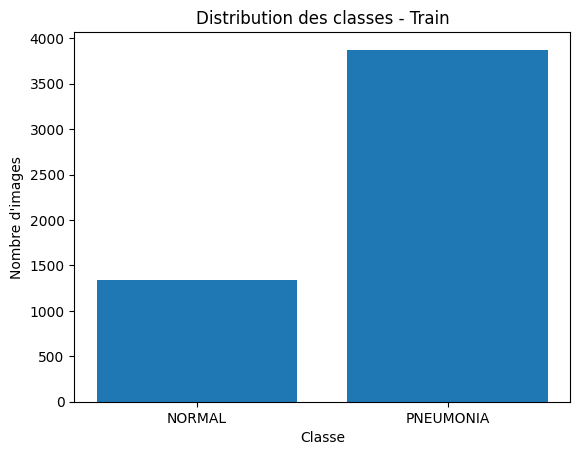

In [12]:
import matplotlib.pyplot as plt

classes = ["NORMAL", "PNEUMONIA"]
counts = [1341, 3875]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()


In [13]:
 #Identifier les éventuels problèmes liés aux images et gérer les erreurs de chargement.
import os
from PIL import Image

dataset_path = "/content/chest_xray_data/chest_xray"
folders = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

valid_images = 0
invalid_images = []    #récpérer path of invalid images

for folder in folders:
    for classe in classes:
        class_path = os.path.join(dataset_path, folder, classe)

        for filename in os.listdir(class_path):
            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()
                valid_images += 1

            except (OSError, ValueError):
                invalid_images.append(image_path)

print("Images valides :", valid_images)
print("Images invalides :", len(invalid_images))
print("Exemples invalides :", invalid_images[:10])

Images valides : 5856
Images invalides : 0
Exemples invalides : []


### Transforme les imgaes en 180*180 et Format RGB

In [14]:
image_path = "/content/chest_xray_data/chest_xray/train/NORMAL/" + os.listdir("/content/chest_xray_data/chest_xray/train/NORMAL")[0]

with Image.open(image_path) as img:
    img_processed = img.convert("RGB").resize((180, 180))

print("Taille :", img_processed.size)
print("Mode :", img_processed.mode)


Taille : (180, 180)
Mode : RGB


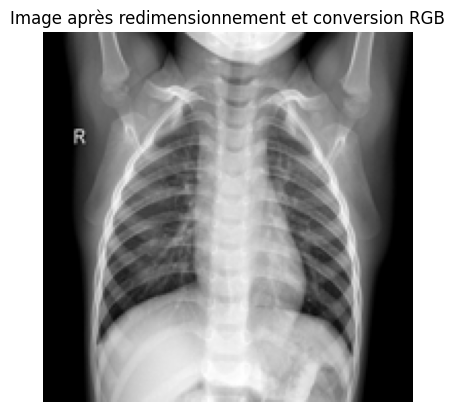

In [15]:
#affiche image aprés la redimension
plt.imshow(img_processed)
plt.title("Image après redimensionnement et conversion RGB")
plt.axis("off")
plt.show()


In [16]:
#transform une version de data and enregiste him in NumPy arrays

dataset_path = "/content/chest_xray_data/chest_xray"

folders = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]
image_size = (180, 180)

data = {}

for folder in folders:
    images = []
    labels = []

    for classe in classes:
        class_path = os.path.join(dataset_path, folder, classe)
        label = classes.index(classe)

        for filename in os.listdir(class_path):
            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img = img.convert("RGB")
                    img = img.resize(image_size)

                    images.append(np.array(img)) #transform images to pixels
                    labels.append(label)

            except (OSError, ValueError) as e:
                print(f"Image ignorée : {image_path} | Erreur : {e}")

    data[folder] = {
        "images": np.array(images, dtype=np.uint8), #stock les images en type   pixels de 0 à 255
        "labels": np.array(labels, dtype=np.int32)
    }

    print(f"{folder} : {len(images)} images traitées")


train : 5216 images traitées
val : 16 images traitées
test : 624 images traitées


In [17]:
for folder in folders:
    X = data[folder]["images"]
    y = data[folder]["labels"]

    print(f"\n{folder.upper()}")
    print("Images :", X.shape)
    print("Labels :", y.shape)
    print("Type :", X.dtype)
    print("Valeur minimale :", X.min())
    print("Valeur maximale :", X.max())



TRAIN
Images : (5216, 180, 180, 3)
Labels : (5216,)
Type : uint8
Valeur minimale : 0
Valeur maximale : 255

VAL
Images : (16, 180, 180, 3)
Labels : (16,)
Type : uint8
Valeur minimale : 0
Valeur maximale : 255

TEST
Images : (624, 180, 180, 3)
Labels : (624,)
Type : uint8
Valeur minimale : 0
Valeur maximale : 255


### La normalisation des photos entre (0 et 1)

In [18]:

# Normalisation des pixels dans la plage [0, 1]

X_train = data["train"]["images"].astype(np.float32) / 255.0   #récupérer images train stock in (data) Numpy array
X_val = data["val"]["images"].astype(np.float32) / 255.0
X_test = data["test"]["images"].astype(np.float32) / 255.0

# Vérification de la normalisation
for name, X in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name} :")
    print("Type :", X.dtype)
    print("Min :", X.min())
    print("Max :", X.max())
    print("-" * 30)


Train :
Type : float32
Min : 0.0
Max : 1.0
------------------------------
Validation :
Type : float32
Min : 0.0
Max : 1.0
------------------------------
Test :
Type : float32
Min : 0.0
Max : 1.0
------------------------------


### Affiche échantillon image  de chaque class

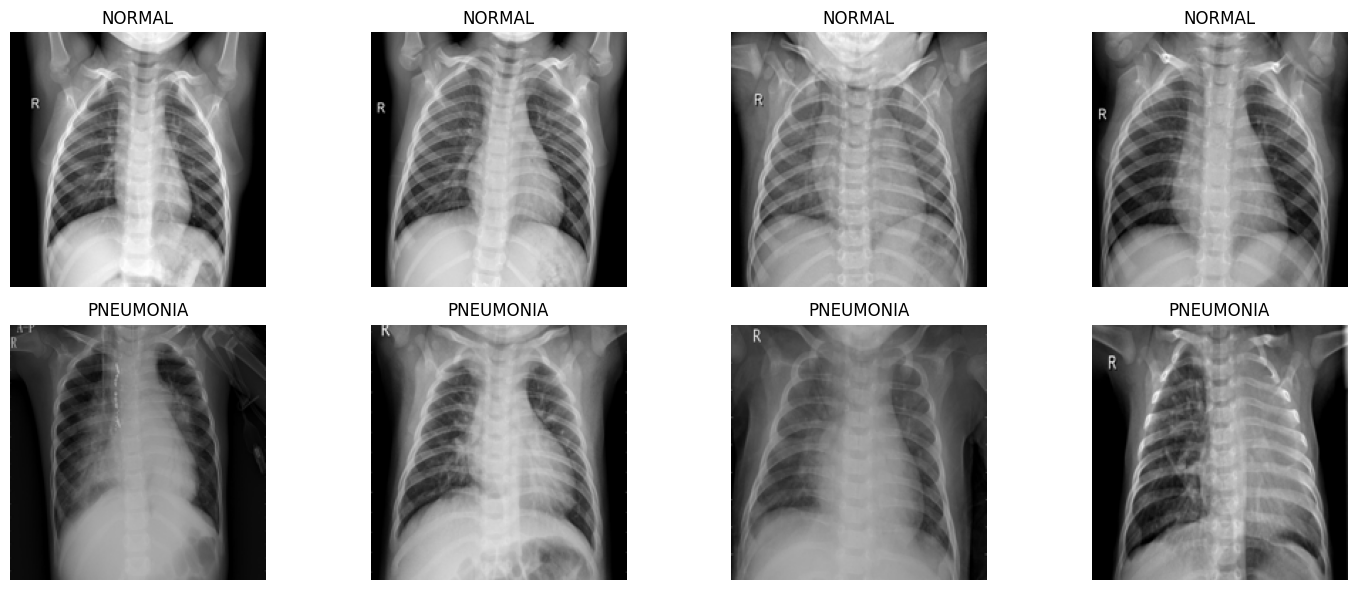

In [19]:
# Noms des classes
classes = ["NORMAL", "PNEUMONIA"]

# Nombre d'images à afficher par classe
n_images = 4

plt.figure(figsize=(15, 6))
y_train = data["train"]["labels"]
for class_id, class_name in enumerate(classes):
    # Récupérer les indices des images de cette classe
    indices = np.where(y_train == class_id)[0][:n_images]

    for i, idx in enumerate(indices):
        plt.subplot(2, n_images, class_id * n_images + i + 1)

        # Afficher l'image
        plt.imshow(X_train[idx])

        # Afficher le nom de la classe
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


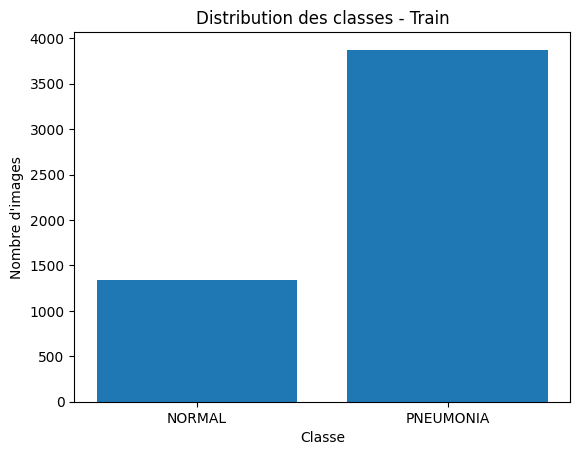

In [20]:
classes = ["NORMAL", "PNEUMONIA"]
counts = [1341, 3875]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

### Etude Désiquilibre de class
en trouve que il ya plus de data anormale (PNEUMONIA) par rapport a (NORMAL)
donc pour résolu se probléme je trouve 4 méthode
-Class weights
-Data augmentation
-Oversampling
-Undersampling
et pour notre Cas pour ne pas perdu de data on va appliquer Class weights(nécessite à donner l'importance dans l'error a la class NORMAL)

# **2_Conception du modèle CNN**

In [22]:
from tensorflow import  keras
data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.03),
    keras.layers.RandomZoom(0.1),
], name="data_augmentation")


In [23]:
#création de Model
import tensorflow as tf
from tensorflow.keras import layers, models


model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),
    data_augmentation,
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"    #extraire des caractéristiques visuelles.
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    #classification
    layers.Flatten(),    #Transforme les caractéristiques en un vecteur.
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    #binary classification(normal/pneumonia)
    layers.Dense(1, activation="sigmoid")
])


In [24]:
#Compiler le modele CNN
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)


In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Définition des hyperparamètres
BATCH_SIZE = 32
EPOCHS = 10

##Vérifier la normalisation  (Avant frain modele)

In [27]:

print("Train :", X_train.shape, X_train.dtype)
print("Validation :", X_val.shape, X_val.dtype)
print("Test :", X_test.shape, X_test.dtype)

print("Valeur minimale :", X_train.min())
print("Valeur maximale :", X_train.max())


Train : (5216, 180, 180, 3) float32
Validation : (16, 180, 180, 3) float32
Test : (624, 180, 180, 3) float32
Valeur minimale : 0.0
Valeur maximale : 1.0


In [28]:
#Configurer EarlyStopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,    #check 3epocks befor stopping
    restore_best_weights=True
)

In [38]:
#configurer ReduceLROnPlateau(C’est un mécanisme qui réduit automatiquement le taux d’apprentissage (Learning Rate) lorsque la performance du modèle ne s’améliore plus)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [39]:
#La division de data de train entre train et val(puisque on'a déja suelemnt 16 images dans val pas suffisant pour evaluation de modele)
from sklearn.model_selection import train_test_split

X_train_new, X_val_new, y_train_new, y_val_new = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Train :", X_train_new.shape, y_train_new.shape)
print("Validation :", X_val_new.shape, y_val_new.shape)
print("Test :", X_test.shape, y.shape)


Train : (4694, 180, 180, 3) (4694,)
Validation : (522, 180, 180, 3) (522,)
Test : (624, 180, 180, 3) (624,)


# **3. Entraînement et optimisation du modèle**

Entraîner le CNN avec model.fit

In [50]:
import time

start_time = time.time()

history = model.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping,reduce_lr]
)

end_time = time.time()
training_duration = end_time - start_time

print(f"Durée de l'entraînement : {training_duration:.2f} secondes")
print(f"Nombre d'epochs effectuées : {len(history.history['loss'])}")

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.9629 - auc: 0.9934 - loss: 0.0970 - precision: 0.9894 - recall: 0.9604 - val_accuracy: 0.9693 - val_auc: 0.9972 - val_loss: 0.0755 - val_precision: 0.9895 - val_recall: 0.9691 - learning_rate: 2.5000e-04
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9696 - auc: 0.9950 - loss: 0.0856 - precision: 0.9909 - recall: 0.9674
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.9678 - auc: 0.9943 - loss: 0.0899 - precision: 0.9906 - recall: 0.9659 - val_accuracy: 0.9636 - val_auc: 0.9952 - val_loss: 0.0970 - val_precision: 0.9920 - val_recall: 0.9588 - learning_rate: 2.5000e-04
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.9661 - auc: 0.9934 - loss: 0.0951 - precision: 0.9877 - recall: 0.9664 - val_accuracy: 0.9617 - val_auc: 0.9962 - val_loss: 0.1011 - val_precision: 0.9920 - val_recall: 0.9562 - learning_r

Visualiser les courbes d'apprentissage : fonction de perte et métriques de performance.

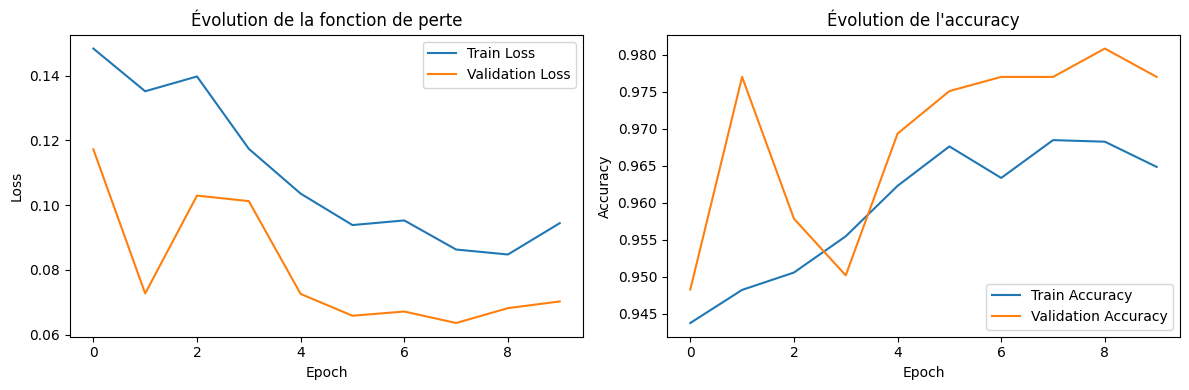

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Évolution de l'accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
best_epoch = history.history["val_loss"].index(
 min(history.history["val_loss"])
) + 1

print("Meilleure epoch selon val_loss :", best_epoch)
print("Meilleure val_loss :", min(history.history["val_loss"]))
print("Meilleure val_accuracy :", max(history.history["val_accuracy"]))

Meilleure epoch selon val_loss : 8
Meilleure val_loss : 0.06355756521224976
Meilleure val_accuracy : 0.9808428883552551


Étudier les effets du déséquilibre des classes et, si nécessaire, utiliser une stratégie de pondération des classes.

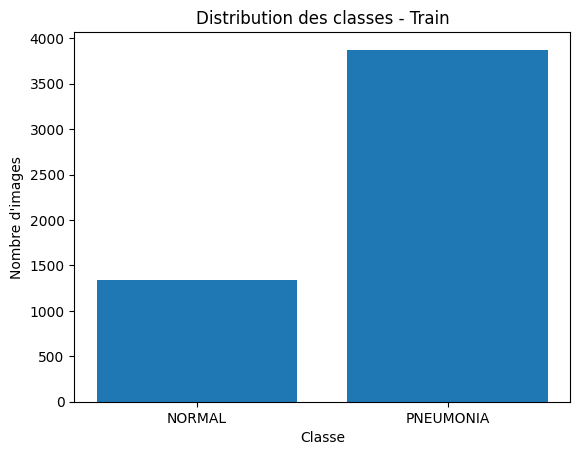

In [46]:
classes = ["NORMAL", "PNEUMONIA"]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

In [49]:
# Sauvegarder les résultats du premier entraînement (Aprés l'ajoute de Early sttoping et ReduceLROnPlateau)
history_before_weights = history
duration_before_weights = training_duration

print("Résultats du premier entraînement sauvegardés.")
print("Nombre d'epochs :", len(history_before_weights.history["loss"]))
print(f"Durée : {duration_before_weights:.2f} secondes")

Résultats du premier entraînement sauvegardés.
Nombre d'epochs : 10
Durée : 71.95 secondes


In [53]:
#Résultats d'entrainement aprées l'ajoute de class_weight
history_with_weights = history
duration_with_weights = training_duration

print("Meilleure val_loss :", min(history.history["val_loss"]))
print("Meilleure val_accuracy :", max(history.history["val_accuracy"]))
print("Durée :", training_duration, "secondes")

Meilleure val_loss : 0.07548477500677109
Meilleure val_accuracy : 0.969348669052124
Durée : 25.52349352836609 secondes


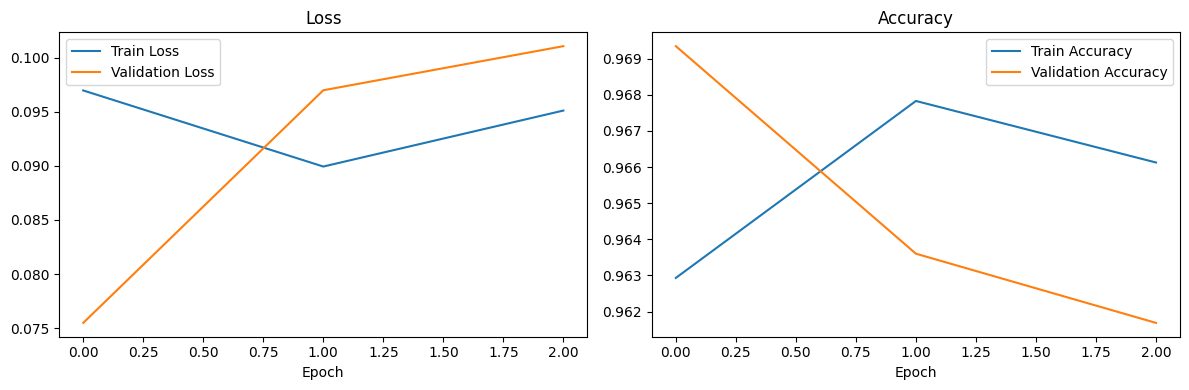

In [54]:
#courbe d'apprentissage  aprées Amélioration de Model avec(class_weight/ReduceLROnPlateau)
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

# **4. Évaluation du modèle**

Évaluer le modèle sur Test

In [59]:
test_results = model.evaluate(X_test, y, verbose=1)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8333 - auc: 0.9341 - loss: 0.5977 - precision: 0.7918 - recall: 0.9949


# Analyse de Model Aprés test
Accuracy : environ 83.33 % des images Le modèle a correctement classé.

AUC( 0,9341):Le modèle il a bonne capacité à distinguer les classes NORMAL et PNEUMONIA.

Loss : 0,5977

Precision :Environ 79.18 % des images prédites comme PNEUMONIA sont vraiment dans cette class

Recall : 99,49 % — Le modèle détecte presque tous les cas de PNEUMONIA, avec très peu de faux négatifs.

In [60]:
from sklearn.metrics import f1_score, confusion_matrix, classification_report, roc_auc_score

y_pred_proba = model.predict(X_test).ravel()
y_pred = (y_pred_proba >= 0.5).astype(int)

print("F1-score :", f1_score(y, y_pred))
print("ROC-AUC :", roc_auc_score(y, y_pred_proba))

print("\nMatrice de confusion :")
print(confusion_matrix(y, y_pred))

print("\nRapport de classification :")
print(classification_report(y, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
F1-score : 0.8818181818181818
ROC-AUC : 0.9560541310541311

Matrice de confusion :
[[132 102]
 [  2 388]]

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.99      0.56      0.72       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



Analyse Matrice de Confusion :(P=PNEUMONIA)
    - TN: 132 — Images NORMAL correctement classées.
    - FP: 102 — Images NORMAL classées à tort comme PNEUMONIA.
    - FN: 2 — Images PNEUMONIA classées à tort comme NORMAL
    - TP: 388 — Images PNEUMONIA correctement détectées.



- F1-score : 0,88 — Bon équilibre entre la précision et le rappel pour la classe PNEUMONIA.
- ROC-AUC : 0,956 — Le modèle distingue bien les deux classes selon ses scores de prédiction.

**Comparer les performances obtenues sur les données d'entraînement, de validation et de test.**

In [62]:
print("Train Accuracy :", max(history_with_weights.history["accuracy"]))
print("Validation Accuracy :", max(history_with_weights.history["val_accuracy"]))
print("Test Accuracy :", test_results[1])

Train Accuracy : 0.9678312540054321
Validation Accuracy : 0.969348669052124
Test Accuracy : 0.8333333134651184
